# Lab Activity 7 Solution: Missing Data Pt. 2, Multinomial Logistic Regression, KNN

*The code in this notebook was generated with the assistance of Claude. I reviewed every explanation and code block prior to submitting, and reworded and/or deleted a number of offered explanations and replaced with my own.*

## Part 1: Missing Data and Imputation

The solution to Part 1 is at the end of `in_class_notebooks/missing_data_and_imputation.ipynb`, in the section "Lab Activity 7, Part 1: Solution".

## Part 2: Multinomial Logistic Regression

### Setup (provided)

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict
from sklearn.metrics import log_loss, accuracy_score, precision_score, recall_score, ConfusionMatrixDisplay

warnings.filterwarnings("ignore")   # This suppresses some of the warning output in the saga solver

col_names = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe", "type"]
glass = pd.read_csv("../../data/glass.csv", header=None, names=col_names)

class_names = {1: "building_float", 2: "building_nonfloat", 3: "vehicle_float",
               5: "containers", 6: "tableware", 7: "headlamps"}
features = ["RI", "Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]

X = glass[features]
y = glass["type"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=113
)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=224)

Helper functions from our ```multinomial_KNN.ipynb``` in-class notebook are below, with accuracy added to `cv_scores`. These are used for every model in Parts 2 and 3.

In [2]:
def cv_scores(model):
    res = cross_validate(model, X_train, y_train, cv=cv, scoring=["neg_log_loss", "accuracy"])
    return {"log loss (mean)": -res["test_neg_log_loss"].mean(),
            "log loss (sd)": res["test_neg_log_loss"].std(),
            "accuracy (mean)": res["test_accuracy"].mean(),
            "accuracy (sd)": res["test_accuracy"].std()}

def cv_pred(model, method="predict"):
    return cross_val_predict(model, X_train, y_train, cv=cv, method=method)

# Class labels in the order sklearn uses them (columns of predict_proba)
classes = np.sort(y_train.unique())
labels = [f"{c}: {class_names[c]}" for c in classes]

### Q1: Data exploration and model baselines

**(a)** Make a table with the mean, standard deviation, min and max of each feature.

In [3]:
# Q1a
X_train.describe().T[["mean", "std", "min", "max"]].round(4)

,mean,std,min,max
RI,1.5184,0.0031,1.5112,1.5339
Na,13.3979,0.8329,10.7300,17.3800
Mg,2.6787,1.4582,0.0000,4.4900
Al,1.4228,0.4932,0.2900,3.5000
Si,72.6588,0.7900,69.8100,75.4100
K,0.4754,0.5678,0.0000,6.2100
Ca,9.0056,1.5304,5.4300,16.1900
Ba,0.1848,0.5230,0.0000,3.1500
Fe,0.0588,0.0966,0.0000,0.5100


**Notes on (a):** The eight oxides are all in the same unit (weight %), but on very different scales: `Si` averages about 73% while `Fe` and `Ba` are usually zero (their medians are 0). `RI` is on a completely different scale (about 1.52, with an SD of 0.003), which is why we standardize before fitting anything.

**(b)** How many fragments of each type are in the training and test sets? Which classes are rare? Which is the most common?

In [4]:
# Q1b
counts = pd.DataFrame({"n (train)": y_train.value_counts().sort_index(),
                       "n (test)": y_test.value_counts().sort_index()})
counts.index = labels
counts

,n (train),n (test)
1: building_float,56,14
2: building_nonfloat,61,15
3: vehicle_float,14,3
5: containers,10,3
6: tableware,7,2
7: headlamps,23,6


**A1b:** `building_nonfloat` (61 training fragments) is the most common class, followed by `building_float` (56). `tableware` (7), `containers` (10), and `vehicle_float` (14) are more rare. The stratified split keeps the same proportions in the test set, which leaves only 2 tableware and 3 each of containers and vehicle_float fragments to test on.

In [5]:
# Q1c + Q1d
# What is the accuracy of a "model" that always predicts the most common class
# Compute the base rate log loss on the training set. 
# The code below should look very similar to what we did in class? 

acc_base = y_train.value_counts(normalize=True).max()
class_props = y_train.value_counts(normalize=True).sort_index().values
ll_base = log_loss(y_train, np.tile(class_props, (len(y_train), 1)))

print(f"(c) Majority-class accuracy: {acc_base:.4f}")
print(f"(d) Base-rate log loss:      {ll_base:.4f}")
print(f"    ln(6):                   {np.log(6):.4f}")

(c) Majority-class accuracy: 0.3567
(d) Base-rate log loss:      1.5049
    ln(6):                   1.7918


**A1c:** 61/171 ≈ 0.357. Always predicting `building_nonfloat` is right about 36% of the time, so any real model needs to beat that.

**A1d:** About 1.505. This is the log loss of predicting the training class proportions (0.33, 0.36, 0.08, 0.06, 0.04, 0.13) for every fragment.

**Q1e** Predicting 1/K for every class gives a log loss of ln K = ln 6 ≈ 1.79. Why is the base-rate log loss from part (d) lower than ln 6?

In [6]:
# Q1e: where the base-rate log loss comes from, class by class
K = len(classes)
breakdown = pd.DataFrame({
    "n (train)": y_train.value_counts().sort_index().values,
    "base-rate prob": class_props,
    "-ln p (base rate)": -np.log(class_props),
    "-ln p (1/K)": -np.log(1 / K),
}, index=labels)

# Each class adds (share of fragments) x (-ln of its predicted prob) to the log loss
breakdown["contribution (base rate)"] = breakdown["base-rate prob"] * breakdown["-ln p (base rate)"]
breakdown["contribution (1/K)"] = breakdown["base-rate prob"] * breakdown["-ln p (1/K)"]

breakdown.round(3)

,n (train),base-rate prob,-ln p (base rate),-ln p (1/K),contribution (base rate),contribution (1/K)
1: building_float,56,0.327,1.116,1.792,0.366,0.587
2: building_nonfloat,61,0.357,1.031,1.792,0.368,0.639
3: vehicle_float,14,0.082,2.503,1.792,0.205,0.147
5: containers,10,0.058,2.839,1.792,0.166,0.105
6: tableware,7,0.041,3.196,1.792,0.131,0.073
7: headlamps,23,0.135,2.006,1.792,0.270,0.241


**A1e:** Because the classes are unbalanced the base rate log loss is lower than ln6. We can see this by comparing base rate probabilities for each class, and how much each of those contributes to the log loss vs 1/6. 

The base-rate "model" puts about 68% of its probability on the two window classes, which is where 68% of the fragments are. The rare classes get less than 1/6 (around 0.17), but there are very few of them. Predicting 1/K is only the best constant prediction when the classes are equally common; otherwise the class proportions do better.

### Q2: Build an unpenalized model (no regularization)

**(a)** The eight oxide columns are weight percentages. Add them up across each row and summarize the result.

In [7]:
# Q2a
oxides = ["Na", "Mg", "Al", "Si", "K", "Ca", "Ba", "Fe"]
glass[oxides].sum(axis=1).describe().round(2)

count    214.00
mean      99.87
std        0.12
min       99.02
25%       99.81
50%       99.89
75%       99.96
max      100.10
dtype: float64

**A2a:** The eight oxides sum to almost exactly 100% for every fragment (mean 99.9, SD 0.1, range 99.0 to 100.1). The reason they are not exactly 100% because the glass has some components that aren't in the dataset, and the measurements have some error. The oxides are the chemical makeup of the glass, so any one of them is almost exactly 100 minus the sum of the other seven. Multicollinearity!

**(b)** Fit a multinomial logistic regression with no penalty in a pipeline with `StandardScaler()`. Report the CV log loss and accuracy, then fit on the full training set and look at the coefficients.

In [8]:
# Q2b
unpen = Pipeline([("scale", StandardScaler()),
                  ("model", LogisticRegression(C=np.inf, max_iter=50000))])
print(pd.Series(cv_scores(unpen)).round(4))

unpen.fit(X_train, y_train)
coef_unpen = pd.DataFrame(unpen.named_steps["model"].coef_.T, index=features,
                          columns=[class_names[c] for c in unpen.classes_])
coef_unpen.round(2)

log loss (mean)    4.2587
log loss (sd)      0.9968
accuracy (mean)    0.6262
accuracy (sd)      0.0745
dtype: float64


,building_float,building_nonfloat,vehicle_float,containers,tableware,headlamps
RI,-21.79,-20.53,-27.30,-20.69,42.17,48.14
Na,-40.19,-44.90,-33.37,-39.14,71.99,85.61
Mg,-13.19,-24.73,-0.10,-19.16,18.25,38.92
Al,-21.38,-21.89,-16.76,-12.41,39.19,33.25
Si,-29.21,-34.10,-25.20,-25.93,43.85,70.59
K,3.77,0.15,6.77,2.81,-61.01,47.50
Ca,-3.96,-14.34,12.78,-3.82,-11.10,20.46
Ba,2.16,-2.31,5.19,1.23,-43.15,36.88
Fe,19.99,20.23,19.62,19.72,-58.81,-20.75


**(c)** Compute the VIF for each of the nine predictors. What does this tell us about the coefficients in part (b)? Relate your answer to part (a).

In [9]:
# Q2c: VIF = diagonal of the inverse correlation matrix (equivalent to statsmodels' variance_inflation_factor on standardized predictors)
vif = pd.Series(np.diag(np.linalg.inv(X_train.corr().values)), index=features)
vif.round(1).sort_values(ascending=False)

Ca    335.0
Mg    291.9
Na     90.5
Si     83.4
K      45.4
Ba     38.5
Al     33.9
RI     11.5
Fe      1.4
dtype: float64

**A2c:** The VIFs are huge: `Ca` ≈ 335, `Mg` ≈ 290, `Na` ≈ 90, `Si` ≈ 80, and only `Fe` is below 10. That is the sum-to-100 constraint from part (a) showing up as near-perfect multicollinearity: each oxide can be predicted almost exactly from the others. With collinear predictors, there is huge variance in the individual coefficients, and the coefficients themselves have large magnitude. Large positive and negative coefficients on different oxides nearly cancel, so many different coefficient vectors give almost the same fit, and the unpenalized fit lands on one with very large, unstable values. 

**Q2d** Compare this model's CV log loss with the base-rate log loss from Q1d. How can a model with over 60% accuracy have a *worse* log loss than a model that uses no predictors at all?

**A2d:** The unpenalized model's CV log loss (about 4) is far worse than the base rate (1.505), even though its accuracy (0.63) is much better than our "model" that only predicted the majority class (0.36). Accuracy only assesses the number of predictions we got right out of the total number of predictions we made. Log loss looks at how much probability the model gave the true class, and that penalty grows quickly as that probability gets close to zero. The huge coefficients produce predicted probabilities very close to 0 or 1, so the roughly 37% of fragments the model gets wrong get a true-class probability near zero, and each one costs a lot (−ln of a very small number). 

### Q3: Build a regularized multinomial logistic regression model

Same `C_values`, `l1_ratios`, and one-standard-error rule as the in-class notebook.

In [10]:
# Q3: fit the grid (table is created but not printed)
def make_model(C, l1_ratio):
    return Pipeline(steps=[
        ("scale", StandardScaler()),
        ("model", LogisticRegression(C=C, l1_ratio=l1_ratio, solver="saga", max_iter=50000, random_state=48)),
    ])

C_values = [0.01, 0.03, 0.1, 0.3, 1, 3, 10, 30, 100, 300, 1000]
l1_ratios = {"lasso": 1, "enet 0.75": 0.75, "enet 0.5": 0.5, "enet 0.25": 0.25, "ridge": 0}

all_results = pd.DataFrame([{"model": name, "C": C, **cv_scores(make_model(C, r))}
                            for name, r in l1_ratios.items() for C in C_values])

**(a)** Plot the mean CV log loss against C for each penalty type, with the base-rate log loss as a reference line. Which penalty and C give the lowest CV log loss? Which model does the one-standard-error rule select, and how many of its 54 coefficients are nonzero?

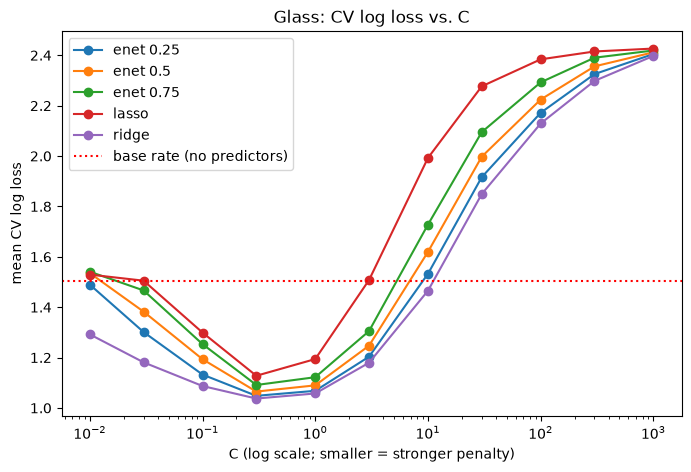

In [11]:
# Q3a: plot
fig, ax = plt.subplots(figsize=(8, 5))
for name, g in all_results.groupby("model"):
    ax.plot(g["C"], g["log loss (mean)"], marker="o", label=name)
ax.axhline(ll_base, color="red", ls=":", label="base rate (no predictors)")
ax.set(xscale="log", xlabel="C (log scale; smaller = stronger penalty)",
       ylabel="mean CV log loss", title="Glass: CV log loss vs. C")
ax.legend()
plt.show()

In [12]:
# Q3a: one-standard-error rule, as in class
best = all_results.loc[all_results["log loss (mean)"].idxmin()]
cutoff = best["log loss (mean)"] + best["log loss (sd)"] / np.sqrt(5)

candidates = all_results[all_results["log loss (mean)"] <= cutoff].copy()
candidates["l1_ratio"] = candidates["model"].map(l1_ratios)
candidates["nonzero coefs (of 54)"] = [
    int((make_model(C, r).fit(X_train, y_train).named_steps["model"].coef_ != 0).sum())
    for C, r in zip(candidates["C"], candidates["l1_ratio"])
]
simplest = candidates.sort_values(["nonzero coefs (of 54)", "C"]).iloc[0]
C_best, method_best, l1_best = simplest["C"], simplest["model"], simplest["l1_ratio"]

print(f"Lowest CV log loss:   {best['model']}, C = {best['C']}  (log loss {best['log loss (mean)']:.4f}, cutoff {cutoff:.4f})")
print(f"Simplest within 1 SE: {method_best} (l1_ratio = {l1_best}), C = {C_best}")
candidates.round(4)

Lowest CV log loss:   ridge, C = 0.3  (log loss 1.0374, cutoff 1.1072)
Simplest within 1 SE: enet 0.75 (l1_ratio = 0.75), C = 0.3


,model,C,log loss (mean),log loss (sd),accuracy (mean),accuracy (sd),l1_ratio,nonzero coefs (of 54)
14,enet 0.75,0.3,1.0912,0.1711,0.5854,0.0575,0.75,27
25,enet 0.5,0.3,1.0650,0.1618,0.5620,0.0643,0.50,30
26,enet 0.5,1.0,1.0897,0.2688,0.6089,0.0653,0.50,43
36,enet 0.25,0.3,1.0482,0.1610,0.5854,0.0710,0.25,39
37,enet 0.25,1.0,1.0681,0.2469,0.6091,0.0825,0.25,49
46,ridge,0.1,1.0871,0.1113,0.5563,0.0715,0.00,54
47,ridge,0.3,1.0374,0.1561,0.5971,0.0627,0.00,54
48,ridge,1.0,1.0575,0.2466,0.6091,0.0825,0.00,54


**A3a:** Ridge with C = 0.3 has the lowest CV log loss (1.0374). The one-standard-error cutoff is 1.0374 + 0.156/√5 ≈ 1.107, and eight models fall under it, all with C between 0.1 and 1. The simplest of them is **elastic net with l1_ratio = 0.75 and C = 0.3**, with 27 of 54 coefficients nonzero (CV log loss 1.091, CV accuracy 0.585). Every model in the plot does best around C = 0.3 to 1, and the curves all turn sharply upward for larger C. 

**(b)** Plot the mean CV accuracy against C for each penalty type. Which C has the highest accuracy? Compare with the log loss and accuracy of the model in part (a).

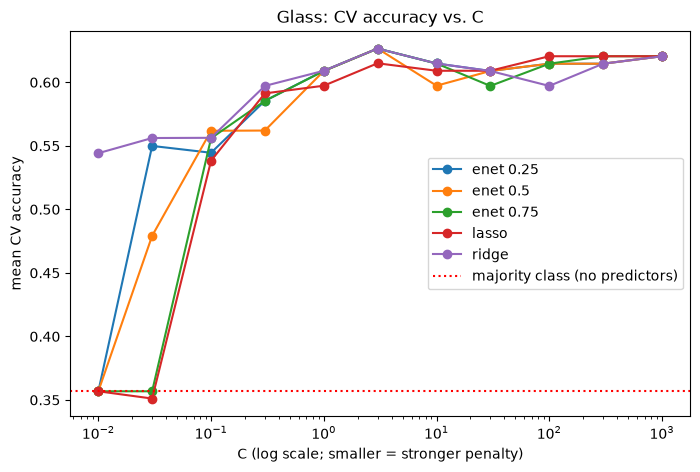

,model,C,log loss (mean),log loss (sd),accuracy (mean),accuracy (sd)
27,enet 0.5,3.0,1.2472,0.5005,0.6266,0.0763
49,ridge,3.0,1.1795,0.4329,0.6266,0.0763
38,enet 0.25,3.0,1.2034,0.4529,0.6266,0.0763
16,enet 0.75,3.0,1.3052,0.5645,0.6266,0.0763
10,lasso,1000.0,2.4267,1.6073,0.6205,0.0814
43,enet 0.25,1000.0,2.4050,1.5992,0.6205,0.0814


In [13]:
# Q3b
fig, ax = plt.subplots(figsize=(8, 5))
for name, g in all_results.groupby("model"):
    ax.plot(g["C"], g["accuracy (mean)"], marker="o", label=name)
ax.axhline(acc_base, color="red", ls=":", label="majority class (no predictors)")
ax.set(xscale="log", xlabel="C (log scale; smaller = stronger penalty)",
       ylabel="mean CV accuracy", title="Glass: CV accuracy vs. C")
ax.legend()
plt.show()

all_results.sort_values("accuracy (mean)", ascending=False).head(6).round(4)

**A3b:** The highest CV accuracy is at **C = 3**, where ridge and all three elastic nets tie at 0.627. Their log losses range from 1.18 (ridge) to 1.31 (enet 0.75), all worse than the 1.09 of the model chosen in part (a), which has accuracy 0.585. The model with the highest accuracy and the one with the lowest log loss are not the same. The accuracy-best model gets about 7 more fragments right (out of 171) but assigns noticeably worse probabilities, which is reflected in the log loss. 

**Q3c** For large values of C (C ≥ 10), every log loss curve sits above the base-rate line. Explain why, including what large C means and your answers in Q2. Why is accuracy higher than the baseline for large C, but log loss gets worse?

**A3c:** C is the inverse of the penalty strength, so large C means almost no regularization. As C grows, every model (ridge, lasso, or in between) approaches the unpenalized fit from Q2, with the same huge, unstable coefficients caused by the collinear oxides. By C = 1000 all five curves have converged to a CV log loss of about 2.4, well above the base rate of 1.5. The accuracy stays above the baseline (about 0.62 vs. 0.36) because the model still gets the *class* right most of the time. The log loss gets worse because the near-zero/near-one probabilities make every mistake expensive, exactly as in Q2d. Regularization doesn't improve the labels much here; what it does is keep the coefficients small enough that the probabilities are honest.

**Q3d** Fit the selected model from part a on the full training set and make a heatmap of its coefficients. Which features have a nonzero coefficient for only one class?

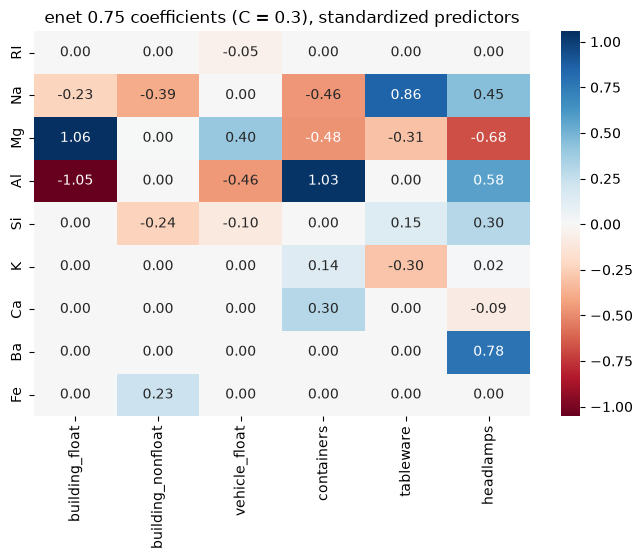

Nonzero for exactly one class: ['RI', 'Ba', 'Fe']


In [14]:
# Q3d
model_best = make_model(C_best, l1_best).fit(X_train, y_train)
coef_table = pd.DataFrame(model_best.named_steps["model"].coef_.T, index=features,
                          columns=[class_names[c] for c in model_best.classes_])

plt.figure(figsize=(8, 5))
sns.heatmap(coef_table, annot=True, fmt=".2f", cmap="RdBu", center=0)
plt.title(f"{method_best} coefficients (C = {C_best}), standardized predictors")
plt.show()

print("Nonzero for exactly one class:", list(coef_table.index[(coef_table != 0).sum(axis=1) == 1]))

**A3d:** Three features are nonzero for only one class: **`Ba`** (headlamps, +0.78), **`Fe`** (building_nonfloat, +0.23), and **`RI`** (vehicle_float, −0.05, barely nonzero). No feature was dropped for every class. `Ba` is the clearest signal in the whole model: barium shows up in nearly all of the headlamp fragments and almost nowhere else. 

**(e)** By what factor does a one standard deviation increase in `Ba` multiply the odds of *headlamps* vs. *building_float*? Repeat for `Mg`, comparing *building_float* vs. *headlamps*.

In [15]:
# Q3e: the odds ratio between two classes uses the DIFFERENCE of their coefficients (softmax has no reference class)
for feat, a, b in [("Ba", "headlamps", "building_float"), ("Mg", "building_float", "headlamps")]:
    diff = coef_table.loc[feat, a] - coef_table.loc[feat, b]
    print(f"{feat}: {a} vs {b}: coefficient difference = {diff:.2f}, odds multiply by e^{diff:.2f} = {np.exp(diff):.2f}")

Ba: headlamps vs building_float: coefficient difference = 0.78, odds multiply by e^0.78 = 2.18
Mg: building_float vs headlamps: coefficient difference = 1.74, odds multiply by e^1.74 = 5.67


**A3e:** With softmax there is no reference class, so the log odds of class A vs. class B is the difference of their coefficients (slide 55).
- `Ba`: 0.78 − 0 = 0.78, so one SD more barium multiplies the odds of headlamps vs. building_float by e^0.78 ≈ **2.2**.
- `Mg`: 1.06 − (−0.68) = 1.74, so one SD more magnesium multiplies the odds of building_float vs. headlamps by e^1.74 ≈ **5.7**.

Both are per standard deviation of the raw feature (about 0.5 weight % for Ba and 1.4 for Mg), because the coefficients are on standardized predictors.

### Q4: Where does the model make mistakes?

Pooled out-of-fold confusion matrix for the selected model, with precision and recall for each class.

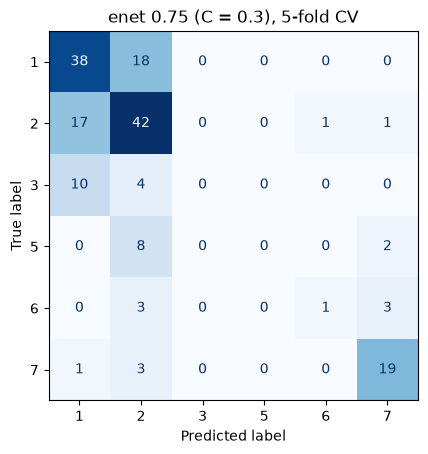

,n (train),precision,recall
1: building_float,56,0.58,0.68
2: building_nonfloat,61,0.54,0.69
3: vehicle_float,14,0.00,0.00
5: containers,10,0.00,0.00
6: tableware,7,0.50,0.14
7: headlamps,23,0.76,0.83


In [16]:
# Q4
pred_lr = cv_pred(make_model(C_best, l1_best))

ConfusionMatrixDisplay.from_predictions(y_train, pred_lr, labels=classes, cmap="Blues", colorbar=False)
plt.title(f"{method_best} (C = {C_best}), 5-fold CV")
plt.show()

per_class_lr = pd.DataFrame({
    "n (train)": y_train.value_counts().sort_index().values,
    "precision": precision_score(y_train, pred_lr, labels=classes, average=None, zero_division=0),
    "recall": recall_score(y_train, pred_lr, labels=classes, average=None, zero_division=0),
}, index=labels)
per_class_lr.round(2)

**A4a:** The model never predicts `vehicle_float` or `containers` correctly. The recall is 0 for both, which means that it never predicts those classes at all. It gets only 1 of 7 `tableware` fragments correct. The two big window classes have recall around 0.7 and the headlamps class has a recall of 0.83. With only 7 to 14 training examples, the rare classes never get enough probability to beat the large window classes.

**A4b:** 10 of the 14 `vehicle_float` fragments are predicted as `building_float` (the other 4 as `building_nonfloat`). The nomenclature ("float") suggests that there might be something similar about the glass making process. (An independent Google study will confirm, but you were not asked to do this!) In addition, if we look at the  class means, we can see that vehicle_float and building_float have almost identical average `Mg`, `Al`, `Ca`, and `RI` implying that it could be difficult to tell them apart. You can get full credit on this question for any well-reasoned answer! 

## Part 3: KNN + Model Comparisons

### Q1: Choosing k and the distance metric

For k = 1, 3, ..., 31 and p ∈ {1, 2}, compute the mean CV log loss and accuracy, and plot both against k.

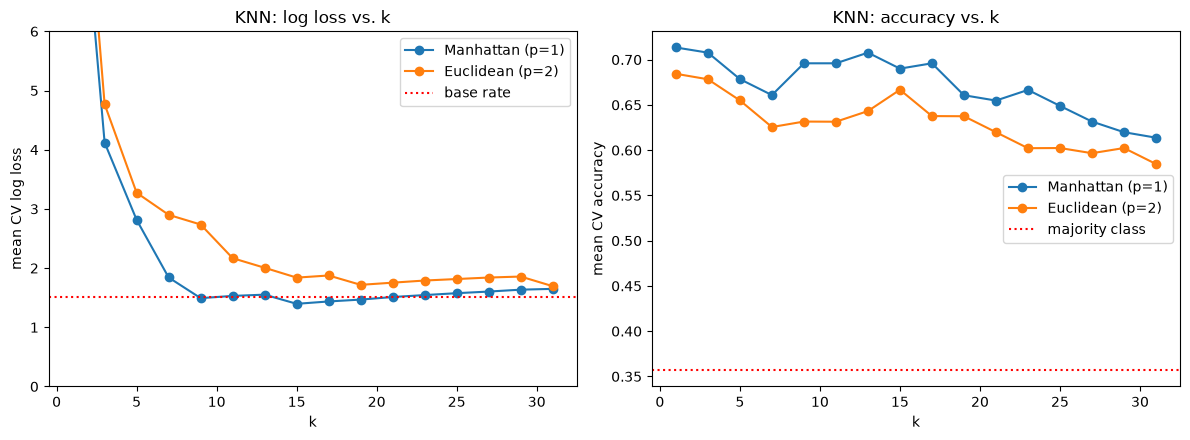

Lowest log loss:   {'k': 15.0, 'p': 1.0, 'log loss (mean)': 1.3967, 'accuracy (mean)': 0.6901}
Highest accuracy:  {'k': 1.0, 'p': 1.0, 'log loss (mean)': 10.3285, 'accuracy (mean)': 0.7134}


In [17]:
# Q1 -- This code should also look very familiar. Pulled from our in-class notebook
def make_knn(k, p=2):
    return Pipeline([("scale", StandardScaler()),
                     ("model", KNeighborsClassifier(n_neighbors=k, p=p))])

k_values = range(1, 32, 2)
knn_results = pd.DataFrame([{"k": k, "p": p, **cv_scores(make_knn(k, p))}
                            for p in [1, 2] for k in k_values])

fig, axes = plt.subplots(1, 2, figsize=(12, 4.5))
for p, label in [(1, "Manhattan (p=1)"), (2, "Euclidean (p=2)")]:
    g = knn_results[knn_results["p"] == p]
    axes[0].plot(g["k"], g["log loss (mean)"], marker="o", label=label)
    axes[1].plot(g["k"], g["accuracy (mean)"], marker="o", label=label)
axes[0].axhline(ll_base, color="red", ls=":", label="base rate")
axes[0].set(xlabel="k", ylabel="mean CV log loss", title="KNN: log loss vs. k", ylim=(0, 6))
axes[1].axhline(acc_base, color="red", ls=":", label="majority class")
axes[1].set(xlabel="k", ylabel="mean CV accuracy", title="KNN: accuracy vs. k")
for ax in axes:
    ax.legend()
plt.tight_layout()
plt.show()

best_ll = knn_results.loc[knn_results["log loss (mean)"].idxmin()]
best_acc = knn_results.loc[knn_results["accuracy (mean)"].idxmax()]

print("Lowest log loss:  ", best_ll[["k", "p", "log loss (mean)", "accuracy (mean)"]].round(4).to_dict())
print("Highest accuracy: ", best_acc[["k", "p", "log loss (mean)", "accuracy (mean)"]].round(4).to_dict())

k_best, p_best = int(best_ll["k"]), int(best_ll["p"])
model_knn = make_knn(k_best, p_best)

Note: the log-loss plot is cut off at 6. k = 1 is off the chart at about 10 to 11.

**A1a:** The lowest CV log loss is **k = 15 with p = 1 (Manhattan)**: log loss 1.397, accuracy 0.690. Manhattan distance has a lower log loss than Euclidean at every k, and Euclidean never gets below the base-rate line at all (its best is 1.69 at k = 31).

**A1b:** Choosing by accuracy would pick **k = 1, p = 1** (accuracy 0.713), whose log loss is 10.3, worse than anything else we have fit. With k = 1, every predicted probability is 0 or 1: the single nearest neighbor's class gets probability 1. When that neighbor is wrong (about 29% of the time), the true class gets probability 0, which sklearn clips to 2.2 × 10⁻¹⁶ before taking the log, adding about 36 per fragment to the log loss. 0.29 × 36 ≈ 10.3, which is the whole log loss. Accuracy only checks whether or not the label is correct. 

### Q2: Where does KNN's log loss come from?

In [18]:
# Q2
proba_knn = cv_pred(model_knn, method="predict_proba")

# Column j of proba_knn is P(class = classes[j]). Pick, for each row, the column of its true class.
true_col = np.searchsorted(classes, y_train.values)
p_true = proba_knn[np.arange(len(y_train)), true_col]

zero = p_true == 0
print(f"(a) {zero.sum()} of {len(y_train)} fragments get P(true class) = 0:")
print(pd.Series(y_train.values[zero]).map(class_names).value_counts().to_string())

eps = np.finfo(float).eps
per_obs = -np.log(np.clip(p_true, eps, 1))       # log loss contribution of each fragment
print(f"\n(b) Each zero-probability fragment adds -ln(eps) = {-np.log(eps):.1f} to the sum")
print(f"    Mean log loss (all fragments):           {per_obs.mean():.4f}   (sklearn: {log_loss(y_train, proba_knn, labels=classes):.4f})")
print(f"    Share of total from the zero fragments:  {per_obs[zero].sum() / per_obs.sum():.1%}")
print(f"    Mean log loss of the remaining fragments: {per_obs[~zero].mean():.4f}")

(a) 3 of 171 fragments get P(true class) = 0:
headlamps     2
containers    1

(b) Each zero-probability fragment adds -ln(eps) = 36.0 to the sum
    Mean log loss (all fragments):           1.3991   (sklearn: 1.3991)
    Share of total from the zero fragments:  45.2%
    Mean log loss of the remaining fragments: 0.7804


**A2a:** 3 of the 171 training fragments get a probability of exactly 0 for their true class: 2 `headlamps` and 1 `containers`. For each of them, none of its 15 nearest neighbors was from its class.

**A2b:** Each one adds −ln(2.2 × 10⁻¹⁶) ≈ 36 to the sum, or 36/171 ≈ 0.21 to the mean log loss. These three fragments account for about **45%** of KNN's total log loss. The other 168 fragments have a mean log loss of about **0.78**, which is lower than the logistic model's 1.09. So KNN's probabilities are actually fine for most fragments; its log loss is dominated by a handful of cases where it says "0% chance" and is wrong. The logistic model can never do that: softmax probabilities are e^z divided by a sum of exponentials, which is always positive.

### Q3: Comparing the two models

**Q3a** CV log loss and accuracy for both models, and a second table with recall for each class.

In [19]:
# Q3a
pred_knn = cv_pred(model_knn)

summary = pd.DataFrame({f"{method_best} (C = {C_best})": cv_scores(make_model(C_best, l1_best)),
                        f"KNN (k = {k_best}, p = {p_best})": cv_scores(model_knn)}).T
summary.round(4)

,log loss (mean),log loss (sd),accuracy (mean),accuracy (sd)
enet 0.75 (C = 0.3),1.0912,0.1711,0.5854,0.0575
"KNN (k = 15, p = 1)",1.3967,0.4744,0.6901,0.0437


In [20]:
recall_tbl = pd.DataFrame({
    "n (train)": y_train.value_counts().sort_index().values,
    "logistic recall": recall_score(y_train, pred_lr, labels=classes, average=None, zero_division=0),
    "KNN recall": recall_score(y_train, pred_knn, labels=classes, average=None, zero_division=0),
}, index=labels)
recall_tbl.round(2)

,n (train),logistic recall,KNN recall
1: building_float,56,0.68,0.96
2: building_nonfloat,61,0.69,0.72
3: vehicle_float,14,0.00,0.00
5: containers,10,0.00,0.20
6: tableware,7,0.14,0.00
7: headlamps,23,0.83,0.78


**A3a:** The logistic model has the lower CV log loss, 1.09 vs. 1.40 for KNN. KNN has the higher CV accuracy, 0.69 vs. 0.59.

**Q3b** Compare the confusion matrices. Where does KNN's extra accuracy come from, and why isn't it a good reason to prefer KNN?

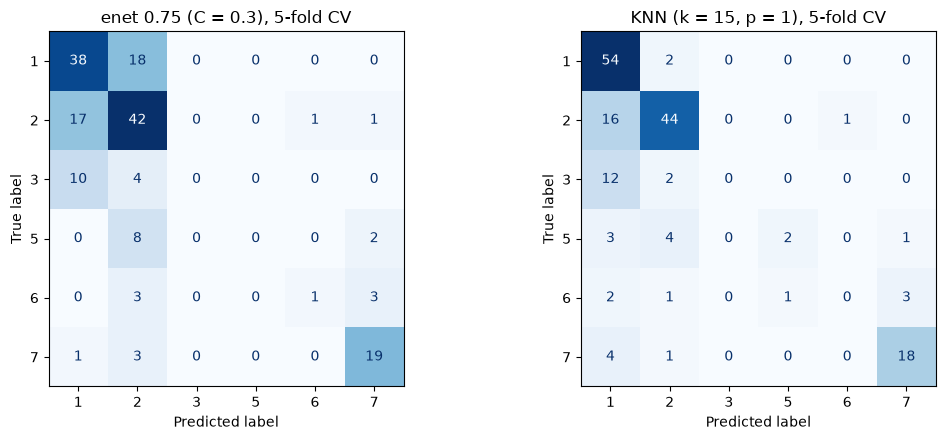

In [21]:
# Q3b
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, pred) in zip(axes, [(f"{method_best} (C = {C_best})", pred_lr), (f"KNN (k = {k_best}, p = {p_best})", pred_knn)]):
    ConfusionMatrixDisplay.from_predictions(y_train, pred, labels=classes, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}, 5-fold CV")
plt.tight_layout()
plt.show()

#print("Fragments predicted as building_float:  logistic", (pred_lr == 1).sum(), "| KNN", (pred_knn == 1).sum())
#print("Correct building_float predictions:     logistic", ((pred_lr == 1) & (y_train == 1)).sum(), "| KNN", ((pred_knn == 1) & (y_train == 1)).sum())

**A3b:** KNN gets 18 more fragments right than the logistic model (118 vs. 100--these numbers come directly from the accuracy and total number of fragments in the training set). Almost all of the gain is in one cell: If we look at the top row of the confusion matrix, KNN predicts 54 of the 56 `building_float` fragments correctly (Class 1), vs. 38 for the logistic model. So of the 18 additional predictions KNN gets correct, 16 of them are from a single class. 

In addition, if we look at the first column, we can see that KNN predicts `building_float` (Class 1) for 91 of the 171 fragments, whereas the logistic model only predicts 66 fragments in Class 1. The extra Class 1 predictions made by KNN are about as accurate as the logistic model's (54/91 vs. 38/66). At first glance it might seem like KNN is a better choice; however, we know that accuracy says nothing about the probabilities or tell us how far off we are, and KNN's probabilities are not as good as the multinomial regression. We see this from the log loss: The KNN log loss (1.40) is only just below the base rate (1.50), because of the zero-probability fragments we explored in Q2. A model chosen on labels alone can be overconfident on new data, and in any application where the probability matters (deciding how much to trust an identification, say) that is the number that counts. Accuracy and recall are still worth reporting because they describe what the chosen model does. Choosing the model itself, particularly for a dataset like this, should rest on log loss.

**One caveat**: log loss is not always the metric that we should reach for first when doing KNN. KNN's predicted probabilities are just the share of the k neighbors in each class, so they can be exactly zero. As we saw in Q2, this adds a heavy penalty to the log loss. The reason that we used log loss here is because we are trying to directly compare KNN with the results of our multinomial logistic regression, and log loss allows us to do an apples to apples comparison. In Lab Activity 8, we will choose k by ROC AUC instead, and look at balanced accuracy, a metric which works better than plain accuracy when the classes are unbalanced. 

**Q3c** Using the recall table, which glass classes does KNN handle better, and which does it not help? What does this suggest about the shape of the boundaries between some of the glass classes?

**A3c:** KNN is much better on `building_float` (recall 0.96 vs. 0.68) and slightly better on `building_nonfloat` (0.72 vs. 0.69) and `containers` (0.20 vs. 0). It does not help the rare classes: `vehicle_float` stays at 0, `tableware` drops from 0.14 to 0, and `headlamps` is slightly worse (0.78 vs. 0.83). The logistic model splits the two building classes almost symmetrically. If you look at the confusion matrix, you can see in the first row that it misclassifies 18 `building_float` fragments (Class 1)and in row 2, we can see 17 `building_nonfloat` fragments (Class 2), that are predicted as `building_float`. This suggests that a linear boundary cuts poorly between them: the two classes overlap in a way that a flat boundary in the 9-dimensional feature space can't follow, while KNN's local, flexible boundary can. For the rare classes, flexibility doesn't help, because with 7 to 14 examples a 15-neighbor vote is almost always dominated by the big window classes.

### Q4: Evaluate on the test set

Refit both models on the full training set, then report test log loss, test accuracy, and a test confusion matrix for each.

                            test log loss  test accuracy
enet 0.75 (C = 0.3)                0.8864         0.6512
KNN (k = 15, p = 1)                0.7538         0.6279
base rate / majority class         1.5243         0.3488


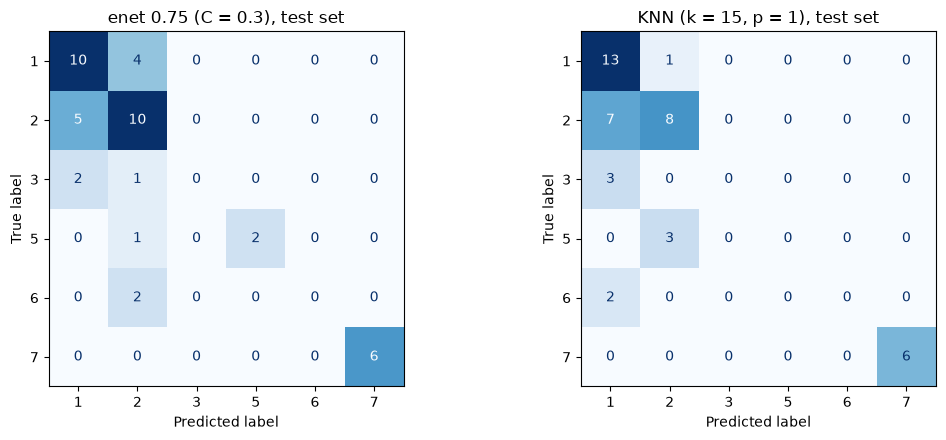

Smallest KNN true-class probability on the test set: 0.067
One zero-probability fragment would add 36.0 / 43 = 0.84 to the test log loss


In [22]:
# Q4
final = {f"{method_best} (C = {C_best})": make_model(C_best, l1_best).fit(X_train, y_train),
         f"KNN (k = {k_best}, p = {p_best})": make_knn(k_best, p_best).fit(X_train, y_train)}

test_results = pd.DataFrame({name: {"test log loss": log_loss(y_test, m.predict_proba(X_test), labels=classes),
                                    "test accuracy": accuracy_score(y_test, m.predict(X_test))}
                             for name, m in final.items()}).T
test_results.loc["base rate / majority class"] = [log_loss(y_test, np.tile(class_props, (len(y_test), 1)), labels=classes),
                                                  (y_test == 2).mean()]
print(test_results.round(4))

fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (name, m) in zip(axes, final.items()):
    ConfusionMatrixDisplay.from_predictions(y_test, m.predict(X_test), labels=classes, ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(f"{name}, test set")
plt.tight_layout()
plt.show()

p_true_test = final[f"KNN (k = {k_best}, p = {p_best})"].predict_proba(X_test)[np.arange(len(y_test)), np.searchsorted(classes, y_test.values)]
print(f"Smallest KNN true-class probability on the test set: {p_true_test.min():.3f}")
print(f"One zero-probability fragment would add {-np.log(eps):.1f} / {len(y_test)} = {-np.log(eps) / len(y_test):.2f} to the test log loss")

**A4a:** No. On the test set KNN has the lower log loss (0.75 vs. 0.89) and the logistic model has the higher accuracy (28/43 vs. 27/43), the reverse of both CV rankings. The log-loss flip is easy to explain: no test fragment gets a probability of 0 from KNN. The code above shows this by calculating `p_true_test`, which gives the KNN predicted probabilities for each fragment in the test set. That calculation shows that the smallest true-class probability is 0.067, so there are no 36-point penalties to the log loss. As we saw in Q2b, any fragment with a 0 probability adds a huge penalty. Without those, the rest of the KNN's probabilities were much more reasonable. The accuracy flip is a single fragment. Both models beat the base rate (1.52) and majority class (0.35) comfortably.

**A4b:** With 2 tableware and 3 each of vehicle_float and containers, per-class recall on the test set can only be 0, 1/3, 2/3, or 1 (0, 1/2, or 1 for tableware). One fragment changes the recall by a third. For example, the logistic model gets 2 of 3 containers right on the test set even though its CV recall for containers was 0. Those numbers say nothing reliable about per-class performance; the pooled out-of-fold results in Parts 2 and 3, which use all 171 training fragments, are the better guide. What we *can* conclude is that the logistic model generalizes about as well as CV predicted overall (test log loss and accuracy are in line with the CV numbers), and that the test set happens not to contain a KNN "zero." If it had contained just one, it would have added 36/43 ≈ **0.84** to KNN's test log loss, taking it from 0.75 to about 1.6, worse than the base rate. That fragility is why we choose the model with cross-validation and look at the test set only once, at the end.

**A note on seeds**. Everyone used the same random seeds for the train/test split and the CV folds so that results would be consistent for grading. Cross-validation reduces how much the results depend on chance, but it doesn't remove that dependence. With a different split or seed, the numbers above would change, and with a dataset this small (only 7 to 14 training fragments in the rare classes) they could change noticeably.

This doesn't mean the model can't be trusted or that the workflow was wrong. It means we should treat the exact numbers as estimates with some uncertainty, and put more weight on the broad conclusions than on small differences. Those broad conclusions are likely to hold on other splits: regularization matters, accuracy and log loss can disagree, and the rare classes are hard to predict. If we needed more precise numbers, repeated cross-validation (```RepeatedStratifiedKFold```) would average over many different fold splits. More data, especially for the rare classes, would help most of all, though that is not a lever we can pull here.